# 04 — Entrenamiento y evaluación de modelos

## Actividad 2.14, fase A

Esta fase fija el experimento y las particiones. **No entrena modelos, no calcula errores de predicción de la bomba y no elige un ganador.**

La selección de candidatos quedó cerrada en la actividad 2.13. Este cuaderno no la reabre. Mapping y surging siguen separados.

Los modelos previstos para una fase posterior, todavía no estimados, son la regresión lineal, el polinomio de grado 2 con cresta, la recta por condición de gas y un bosque aleatorio poco profundo. En mapping se estudiará el cociente respecto de la curva de agua solo si puede hacerse sin usar una curva de prueba.


## 4.1. Introducción

Se quiere predecir `dp2_3_psi`, el incremento de presión leído como el de la etapa 3, en psi. La certeza de ese enlace es media y está en el diccionario. El gas libre disminuye ese incremento. La actividad 2.13 vio, sin ajustar nada, que las curvas de agua bajan al subir el caudal y que la mayoría de los puntos con gas quedan por debajo del agua cercana. Eso no dice qué ecuación predice una curva dejada fuera.

El resultado útil será un error medido al reservar curvas completas. El error de entrenamiento no sirve para elegir el modelo.


## 4.2. Hipótesis

Siguen abiertas. Esta fase no las contrasta.

- **H1.** Un polinomio de grado 2, o una recta distinta por la condición ya escrita, tendrá menor error absoluto medio externo que la recta global. Si no ocurre, la recta global sigue siendo la referencia.
- **H2.** A velocidad y presión fijas, la predicción no sube de forma sistemática al aumentar el gas dentro del rango de la curva. Una subida local no se llamará cambio de régimen sin una comprobación aparte.
- **H3.** Con 30 y 18 curvas, el bosque poco profundo no mejora a la recta de manera estable.
- **H4.** En mapping, la curva de agua de la misma hoja y velocidad ayuda a leer la degradación. No es la presión normalizada de Zhu et al. (2018), porque falta la densidad.

La pregunta de la actividad es cuál candidato predice mejor cada protocolo. No se responde aquí.


## 4.3. Materiales y métodos

**Datos.** Mendeley Data, DOI 10.17632/fk2b4r69bs.1, licencia CC BY 4.0, serie sin isopropanol. Se leen los CSV de la actividad 2.12. No se reescriben.

**Objetivo.** `dp2_3_psi`.

**Predictores de mapping.** Caudal de líquido en bpd, indicador de `Single Phase`, Qgd sin rellenar el vacío, velocidad en rpm y presión del separador en psig.

**Predictores de surging.** `gvf0_porcentaje`, fracción de QBEP, velocidad y presión. La fracción es el bloque de líquido. GVF0 es el gas continuo. No son la misma variable.

**No son predictores.** Fila, archivo, posiciones de columna, identificador de curva y `origen_velocidad`. La hoja no entra como texto: la presión ya está en `psep_psig`.

**Semilla.** 214. El reparto externo no sortea curvas. La semilla queda para cualquier sorteo de una fase posterior.

**Validación prevista.** Tres pliegues externos por protocolo. La unidad es la curva. Dentro del entrenamiento de cada pliegue, un `GroupKFold` elegirá más adelante la penalización y la profundidad. Ese anillo no publica el error.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.model_selection import GroupKFold


def encontrar_raiz_laboratorio() -> Path:
    candidato = Path.cwd().resolve()
    for _ in range(6):
        if (candidato / "data" / "raw" / "mapping.xlsx").is_file() and (
            candidato / "data" / "raw" / "surging.xlsx"
        ).is_file():
            return candidato
        if candidato.parent == candidato:
            break
        candidato = candidato.parent
    raise FileNotFoundError("No se encontró el laboratorio.")


RAIZ = encontrar_raiz_laboratorio()
sys.path.insert(0, str(RAIZ / "src"))
from esp_datascience.particiones import SEMILLA
from esp_datascience.rutas import huella_sha256

HUELLAS = {
    "data/raw/mapping.xlsx": "3b933ca84911484f5d912a44b025f5589abaf5ebc2b0426bf80c083869762bda",
    "data/raw/surging.xlsx": "acdcc6c5fc3d8969280c8712c45657fbb863f163a60829584fece5abf75f28cd",
    "data/processed/mapping_long.csv": "ff68e36703d3d3901b8bd964008c49b062afa9d89a817b9d66e7849f9b400648",
    "data/processed/surging_long.csv": "f58e8e2cac74acdf2081479ec8769422f39c4e4665f5b3ff472df4a70b15bd96",
}
for relativo, esperada in HUELLAS.items():
    if huella_sha256(RAIZ / relativo) != esperada:
        raise RuntimeError(f"Cambió la huella de {relativo}.")
    print(f"{relativo}: huella igual")

mapping = pd.read_csv(RAIZ / "data" / "processed" / "mapping_long.csv")
surging = pd.read_csv(RAIZ / "data" / "processed" / "surging_long.csv")
if len(mapping) != 570 or len(surging) != 387:
    raise RuntimeError("Los conteos ya no son los de la actividad 2.12.")
print(f"numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}")
print(f"Semilla fijada: {SEMILLA}. Mapping {len(mapping)} filas. Surging {len(surging)} filas.")
print("Los CSV no se modifican.")


data/raw/mapping.xlsx: huella igual
data/raw/surging.xlsx: huella igual
data/processed/mapping_long.csv: huella igual
data/processed/surging_long.csv: huella igual
numpy 2.5.4, pandas 3.0.6, scikit-learn 1.9.1
Semilla fijada: 214. Mapping 570 filas. Surging 387 filas.
Los CSV no se modifican.


## 4.4. Preparación

Una curva es la terna hoja, velocidad y condición. En mapping la condición es `Single Phase` o un Qgd. En surging es la fracción de QBEP. Los puntos de una terna son un solo ensayo.

`qgd` vacío es agua. No es un caudal de gas igual a cero.


In [2]:
HOJAS = ("50psig", "100psig", "150psig")
FRACCIONES = ("0.75Qbep", "Qbep", "1.25Qbep")
PREDICTORES_MAPPING = ("ql_bpd", "es_monofasica", "qgd", "velocidad_rpm", "psep_psig")
PREDICTORES_SURGING = ("gvf0_porcentaje", "fraccion_qbep", "velocidad_rpm", "psep_psig")
PROHIBIDOS = {
    "archivo", "hoja", "fila", "columna_condicion", "columna_caudal", "columna_dp",
    "columna_gvf", "curva_id", "origen_velocidad", "fila_celda_velocidad",
    "columna_celda_velocidad", "valor_celda_velocidad", "pliegue",
}


def identificador_curva(tabla: pd.DataFrame) -> pd.Series:
    return (
        tabla["hoja"].astype(str)
        + "|"
        + tabla["velocidad_rpm"].astype(int).astype(str)
        + "|"
        + tabla["condicion"].astype(str)
    )


def entradas_mapping(tabla: pd.DataFrame) -> pd.DataFrame:
    es_monofasica = tabla["condicion"].eq("Single Phase")
    if not np.array_equal(es_monofasica.to_numpy(), tabla["qgd"].isna().to_numpy()):
        raise ValueError("El vacío de qgd ya no coincide con Single Phase.")
    entradas = pd.DataFrame(
        {
            "ql_bpd": tabla["ql_bpd"].to_numpy(),
            "es_monofasica": es_monofasica.to_numpy(),
            "qgd": tabla["qgd"].to_numpy(),
            "velocidad_rpm": tabla["velocidad_rpm"].to_numpy(),
            "psep_psig": tabla["psep_psig"].to_numpy(),
        }
    )
    if entradas.loc[entradas["es_monofasica"], "qgd"].notna().any():
        raise ValueError("qgd de agua fue rellenado.")
    return entradas


entradas_m = entradas_mapping(mapping)
entradas_s = surging.loc[:, list(PREDICTORES_SURGING)].copy()
if set(entradas_m.columns) & PROHIBIDOS or set(entradas_s.columns) & PROHIBIDOS:
    raise RuntimeError("Un metadato entró como predictor.")
print("Predictores de mapping:", list(entradas_m.columns))
print("Filas de agua con qgd vacío:", int(entradas_m["es_monofasica"].sum()))
print("Predictores de surging:", list(entradas_s.columns), "celdas vacías:", int(entradas_s.isna().sum().sum()))
print("Curvas:", identificador_curva(mapping).nunique(), "mapping;", identificador_curva(surging).nunique(), "surging.")
celda = mapping["origen_velocidad"].eq("celda")
print("Velocidad leída en la celda:", int(celda.sum()), "filas;", sorted(mapping.loc[celda, "hoja"].unique()))


Predictores de mapping: ['ql_bpd', 'es_monofasica', 'qgd', 'velocidad_rpm', 'psep_psig']
Filas de agua con qgd vacío: 87
Predictores de surging: ['gvf0_porcentaje', 'fraccion_qbep', 'velocidad_rpm', 'psep_psig'] celdas vacías: 0
Curvas: 30 mapping; 18 surging.
Velocidad leída en la celda: 186 filas; ['50psig']


## 4.5. Particiones

`GroupKFold` no parte una curva. Tampoco equilibra velocidad, presión y condición. En estas tablas, uno de sus cinco pliegues de mapping se queda sin 100 psig, y uno de sus tres pliegues de surging se queda sin la fracción 1,25. Esos cortes no servirían para decir que un modelo cubre el dominio. Se muestran para justificar otro reparto. No se usan para entrenar.

El reparto adoptado tiene tres pliegues. Cada curva va a uno solo. Mapping reserva 10 curvas por pliegue y surging reserva 6. Las filas no se equilibran, porque las curvas tienen distinto largo. La comparación futura pesará cada curva por igual.

En mapping, la curva de agua no cae en el mismo pliegue que el gas de su hoja y velocidad. Así, al predecir ese gas, el agua está del lado del entrenamiento. Al ajustar, solo la mitad de las curvas con gas del entrenamiento tienen su agua también en el entrenamiento. La otra mitad no podrá entrar en el cociente: su agua está en la prueba. Esta fase no calcula ese cociente.

En surging, cada pliegue ve las tres fracciones en la prueba y en el entrenamiento. Una recta por fracción se puede estimar. La fracción no se confunde con GVF0.

Dejar fuera todas las curvas de un mismo Qgd, para probar una condición nunca vista, es otro experimento. Ahí la recta de esa etiqueta no tiene coeficientes. No se ejecuta ahora.


In [3]:
def diagnostico_groupkfold(tabla: pd.DataFrame, n_splits: int, nombre: str) -> None:
    grupos = identificador_curva(tabla).to_numpy()
    print(f"GroupKFold de {nombre}, {n_splits} cortes. No es el reparto adoptado.")
    for indice, (_entrenamiento, prueba) in enumerate(GroupKFold(n_splits).split(tabla, groups=grupos)):
        sub = tabla.iloc[prueba]
        velocidades = sorted(int(v) for v in sub["velocidad_rpm"].unique())
        presiones = sorted(sub["hoja"].unique())
        motivos = []
        if set(velocidades) != {1800, 3500}:
            motivos.append("falta una velocidad")
        if set(presiones) != set(HOJAS):
            motivos.append("falta una presión")
        faltan = sorted(set(tabla["condicion"]) - set(sub["condicion"]))
        if faltan:
            motivos.append("faltan " + ", ".join(faltan))
        aviso = (" — " + "; ".join(motivos)) if motivos else ""
        print(
            f"  pliegue {indice}: {identificador_curva(sub).nunique()} curvas, "
            f"velocidades {velocidades}, hojas {presiones}{aviso}"
        )


diagnostico_groupkfold(mapping, 5, "mapping")
diagnostico_groupkfold(surging, 3, "surging")


GroupKFold de mapping, 5 cortes. No es el reparto adoptado.
  pliegue 0: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.02, Qgd=0.03, Qgd=0.05
  pliegue 1: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.005, Qgd=0.015, Qgd=0.04, Single Phase
  pliegue 2: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.01, Qgd=0.04
  pliegue 3: 6 curvas, velocidades [1800, 3500], hojas ['150psig', '50psig'] — falta una presión; faltan Qgd=0.03, Qgd=0.04, Qgd=0.05
  pliegue 4: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.005, Qgd=0.01, Qgd=0.015, Qgd=0.02
GroupKFold de surging, 3 cortes. No es el reparto adoptado.
  pliegue 0: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig']
  pliegue 1: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan 1.25Qbep
  pliegue 2: 6 curvas, velocid

In [4]:
def pliegue_mapping(hoja: str, velocidad: int, condicion: str) -> int:
    indice = HOJAS.index(hoja)
    velocidad_binaria = 0 if int(velocidad) == 1800 else 1
    if condicion == "Single Phase":
        return (indice + velocidad_binaria) % 3
    if condicion == "Qgd=0.01":
        return (indice + velocidad_binaria + 1) % 3
    if condicion == "Qgd=0.005":
        return (indice + 1) % 3
    if condicion == "Qgd=0.015":
        return (indice + 2) % 3
    if condicion in {"Qgd=0.02", "Qgd=0.04"}:
        return indice % 3
    if condicion in {"Qgd=0.03", "Qgd=0.05"}:
        return (indice + 2) % 3
    raise ValueError(condicion)


def pliegue_surging(hoja: str, condicion: str) -> int:
    return (FRACCIONES.index(condicion) - HOJAS.index(hoja)) % 3


def marcar(tabla: pd.DataFrame, protocolo: str) -> pd.DataFrame:
    copia = tabla.copy()
    copia["curva_id"] = identificador_curva(copia)
    if protocolo == "mapping":
        pares = zip(copia["hoja"], copia["velocidad_rpm"], copia["condicion"], strict=True)
        copia["pliegue"] = [pliegue_mapping(h, v, c) for h, v, c in pares]
    else:
        pares = zip(copia["hoja"], copia["condicion"], strict=True)
        copia["pliegue"] = [pliegue_surging(h, c) for h, c in pares]
    return copia


def curvas_de(tabla: pd.DataFrame) -> pd.DataFrame:
    return (
        tabla.groupby("curva_id", sort=False)
        .agg(
            pliegue=("pliegue", "first"),
            n_pliegues=("pliegue", "nunique"),
            hoja=("hoja", "first"),
            velocidad_rpm=("velocidad_rpm", "first"),
            condicion=("condicion", "first"),
            n_filas=("curva_id", "size"),
            origen_velocidad=("origen_velocidad", "first"),
        )
        .reset_index()
    )


def revisar(curvas: pd.DataFrame, prueba: set[str], entrenamiento: set[str]) -> dict:
    compartidas = prueba & entrenamiento
    if compartidas:
        raise RuntimeError(f"Fuga de curva: {sorted(compartidas)[0]}")
    lado_prueba = curvas[curvas["curva_id"].isin(prueba)]
    lado_entrenamiento = curvas[curvas["curva_id"].isin(entrenamiento)]
    faltan = sorted(set(lado_prueba["condicion"]) - set(lado_entrenamiento["condicion"]))
    return {
        "n_curvas_prueba": len(prueba),
        "n_curvas_entrenamiento": len(entrenamiento),
        "n_filas_prueba": int(lado_prueba["n_filas"].sum()),
        "velocidades": sorted(int(v) for v in lado_prueba["velocidad_rpm"].unique()),
        "hojas": sorted(lado_prueba["hoja"].unique()),
        "n_condiciones": int(lado_prueba["condicion"].nunique()),
        "condiciones_ausentes_en_entrenamiento": faltan,
    }


mapping_p = marcar(mapping, "mapping")
surging_p = marcar(surging, "surging")
curvas_m = curvas_de(mapping_p)
curvas_s = curvas_de(surging_p)
if (curvas_m["n_pliegues"] != 1).any() or (curvas_s["n_pliegues"] != 1).any():
    raise RuntimeError("Una curva quedó partida.")

filas_resumen = []
for nombre, curvas in (("mapping", curvas_m), ("surging", curvas_s)):
    for pliegue, grupo in curvas.groupby("pliegue"):
        prueba = set(grupo["curva_id"])
        entrenamiento = set(curvas.loc[curvas["pliegue"] != pliegue, "curva_id"])
        filas_resumen.append({"protocolo": nombre, "pliegue": int(pliegue), **revisar(curvas, prueba, entrenamiento)})
resumen = pd.DataFrame(filas_resumen)
if resumen["condiciones_ausentes_en_entrenamiento"].map(len).any():
    raise RuntimeError("Hay una condición de prueba que el entrenamiento no vio.")
if not resumen["velocidades"].map(lambda valores: valores == [1800, 3500]).all():
    raise RuntimeError("Un pliegue perdió una velocidad.")
if not resumen["hojas"].map(lambda valores: set(valores) == set(HOJAS)).all():
    raise RuntimeError("Un pliegue perdió una presión.")
display(resumen)
print("Curvas de prueba, suma por protocolo:", resumen.groupby("protocolo")["n_curvas_prueba"].sum().to_dict())

from esp_datascience.particiones import pliegue_mapping as pliegue_mapping_modulo
from esp_datascience.particiones import pliegue_surging as pliegue_surging_modulo

igual_m = all(
    pliegue_mapping(h, v, c) == pliegue_mapping_modulo(h, v, c)
    for h, v, c in curvas_m[["hoja", "velocidad_rpm", "condicion"]].itertuples(index=False)
)
igual_s = all(
    pliegue_surging(h, c) == pliegue_surging_modulo(h, c)
    for h, c in curvas_s[["hoja", "condicion"]].itertuples(index=False)
)
if not igual_m or not igual_s:
    raise RuntimeError("El cuaderno y el módulo no asignan el mismo pliegue.")
print("El módulo src/esp_datascience/particiones.py asigna los mismos pliegues.")


,protocolo,pliegue,n_curvas_prueba,n_curvas_entrenamiento,n_filas_prueba,velocidades,hojas,n_condiciones,condiciones_ausentes_en_entrenamiento
0,mapping,0,10,20,200,"[1800, 3500]","[100psig, 150psig, 50psig]",8,[]
1,mapping,1,10,20,192,"[1800, 3500]","[100psig, 150psig, 50psig]",8,[]
2,mapping,2,10,20,178,"[1800, 3500]","[100psig, 150psig, 50psig]",8,[]
3,surging,0,6,12,130,"[1800, 3500]","[100psig, 150psig, 50psig]",3,[]
4,surging,1,6,12,132,"[1800, 3500]","[100psig, 150psig, 50psig]",3,[]
5,surging,2,6,12,125,"[1800, 3500]","[100psig, 150psig, 50psig]",3,[]


Curvas de prueba, suma por protocolo: {'mapping': 30, 'surging': 18}
El módulo src/esp_datascience/particiones.py asigna los mismos pliegues.


In [5]:
def internos(curvas: pd.DataFrame, pliegue_externo: int, n_cortes: int) -> pd.DataFrame:
    entrenamiento = curvas[curvas["pliegue"] != pliegue_externo].reset_index(drop=True)
    grupos = entrenamiento["curva_id"].to_numpy()
    salida = []
    cortes = GroupKFold(n_splits=n_cortes).split(np.zeros((len(entrenamiento), 1)), groups=grupos)
    for indice, (_tr, te) in enumerate(cortes):
        prueba = set(entrenamiento.iloc[te]["curva_id"])
        resto = set(entrenamiento["curva_id"]) - prueba
        salida.append({"pliegue_externo": pliegue_externo, "pliegue_interno": indice, **revisar(entrenamiento, prueba, resto)})
    return pd.DataFrame(salida)


internos_m = pd.concat([internos(curvas_m, pliegue, 4) for pliegue in range(3)], ignore_index=True)
internos_s = pd.concat([internos(curvas_s, pliegue, 3) for pliegue in range(3)], ignore_index=True)
for nombre, tabla in (("mapping", internos_m), ("surging", internos_s)):
    if tabla["condiciones_ausentes_en_entrenamiento"].map(len).any():
        raise RuntimeError(f"Corte interno de {nombre} sin la condición de prueba.")
    if not tabla["velocidades"].map(lambda valores: valores == [1800, 3500]).all():
        raise RuntimeError(f"Corte interno de {nombre} sin una velocidad.")
    if not tabla["hojas"].map(lambda valores: set(valores) == set(HOJAS)).all():
        raise RuntimeError(f"Corte interno de {nombre} sin una presión.")
print(f"Internos de mapping: {len(internos_m)} cortes, {sorted(internos_m['n_curvas_prueba'].unique())} curvas de prueba.")
print(f"Internos de surging: {len(internos_s)} cortes, {sorted(internos_s['n_curvas_prueba'].unique())} curvas de prueba.")
print("Ningún corte interno pierde velocidad, presión ni la condición que evalúa.")


Internos de mapping: 12 cortes, [np.int64(5)] curvas de prueba.
Internos de surging: 9 cortes, [np.int64(4)] curvas de prueba.
Ningún corte interno pierde velocidad, presión ni la condición que evalúa.


,pliegue_de_prueba,curvas_con_gas_en_prueba,su_agua_esta_en_entrenamiento,curvas_con_gas_en_entrenamiento,su_agua_tambien_en_entrenamiento
0,0,8,8,16,8
1,1,8,8,16,8
2,2,8,8,16,8


Las 24 curvas con gas se predicen, en este diseño, con el agua de su hoja y velocidad dentro del entrenamiento. Para ajustar el cociente solo hay 8 de 16 curvas con gas cuya agua también está en el entrenamiento. Las otras 8 quedan fuera de ese ajuste, porque su agua es una curva de prueba. No se calculó ningún cociente.

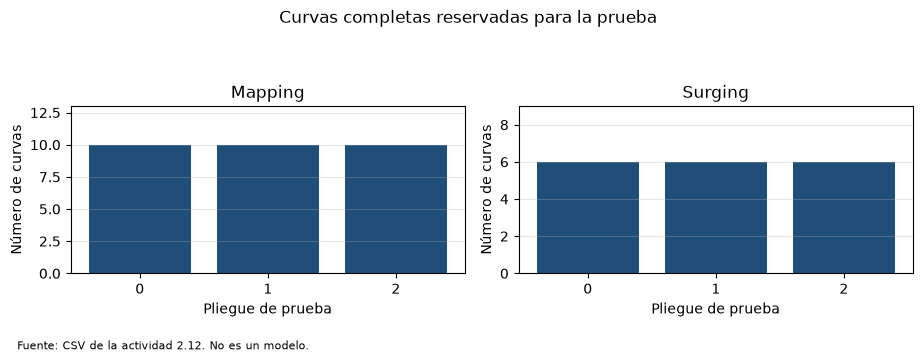

In [6]:
agua = curvas_m.loc[curvas_m["condicion"].eq("Single Phase"), ["hoja", "velocidad_rpm", "pliegue"]]
agua = agua.rename(columns={"pliegue": "pliegue_agua"})
gas = curvas_m.loc[~curvas_m["condicion"].eq("Single Phase")].merge(agua, on=["hoja", "velocidad_rpm"])
if (gas["pliegue"] == gas["pliegue_agua"]).any():
    raise RuntimeError("Gas y agua de la misma hoja y velocidad cayeron en el mismo pliegue.")

conteos = []
for pliegue in range(3):
    prueba = gas[gas["pliegue"].eq(pliegue)]
    entreno = gas[~gas["pliegue"].eq(pliegue)]
    conteos.append(
        {
            "pliegue_de_prueba": pliegue,
            "curvas_con_gas_en_prueba": len(prueba),
            "su_agua_esta_en_entrenamiento": int((prueba["pliegue_agua"] != pliegue).sum()),
            "curvas_con_gas_en_entrenamiento": len(entreno),
            "su_agua_tambien_en_entrenamiento": int((entreno["pliegue_agua"] != pliegue).sum()),
        }
    )
display(pd.DataFrame(conteos))
display(Markdown(
    "Las 24 curvas con gas se predicen, en este diseño, con el agua de su hoja y velocidad "
    "dentro del entrenamiento. Para ajustar el cociente solo hay 8 de 16 curvas con gas cuya agua "
    "también está en el entrenamiento. Las otras 8 quedan fuera de ese ajuste, porque su agua es una curva de prueba. "
    "No se calculó ningún cociente."
))

fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.5))
for eje, curvas, titulo in ((ejes[0], curvas_m, "Mapping"), (ejes[1], curvas_s, "Surging")):
    cuenta = curvas.groupby("pliegue").size()
    eje.bar(cuenta.index.astype(str), cuenta.to_numpy(), color="#1f4e79")
    eje.set_xlabel("Pliegue de prueba")
    eje.set_ylabel("Número de curvas")
    eje.set_title(titulo)
    eje.set_ylim(0, float(cuenta.max()) + 3)
    eje.grid(True, axis="y", alpha=0.3)
fig.suptitle("Curvas completas reservadas para la prueba")
fig.text(0.01, 0.01, "Fuente: CSV de la actividad 2.12. No es un modelo.", fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 0.90))
plt.show()


## Cierre de la fase A

Queda comprobado en esta ejecución:

- 570 y 387 filas, 30 y 18 curvas, huellas iguales a las publicadas.
- Ninguna curva está en entrenamiento y en prueba a la vez, ni en el pliegue externo ni en el interno.
- Cada pliegue externo tiene 1800 y 3500 rpm, las tres presiones y todas las condiciones de su protocolo en ambos lados.
- El anillo interno hereda esa cobertura: 4 cortes de 5 curvas en mapping y 3 cortes de 4 curvas en surging.
- `qgd` sigue vacío en las 87 filas de agua. `origen_velocidad` no es predictor.
- La repetición solo con velocidad de celda usará 186 filas de `50psig`. Cambia el dominio: ya no hay tres presiones. No se ejecuta ahora.

No se ajustó la recta, ni el polinomio, ni la recta por condición, ni el bosque, ni el cociente respecto del agua.

## Riesgos para la fase siguiente

- Los pliegues de mapping tienen 200, 192 y 178 filas. Un promedio por fila favorece a las curvas largas. La comparación principal debe promediar curvas.
- Qgd de 0,005 y de 0,015 solo existen a 1800 rpm. Llevar esa etiqueta a 3500 rpm sería extrapolación.
- La velocidad de mapping en 100 y 150 psig viene del diseño. Una conclusión sobre la velocidad tendrá que repetirse sin esas filas, sabiendo que entonces solo queda 50 psig.
- El cociente de agua no es todavía un competidor: el ajuste solo verá 8 curvas con gas por pliegue.
- Probar un Qgd completamente nuevo es otro diseño. Estos pliegues no lo hacen.

La fase B, si se autoriza, estimará solo la recta y el polinomio con cresta, sobre estos cortes.
